# Propensão à subscrição de depósito a prazo — Regressão Logística

**Objetivo:** estimar a probabilidade de um cliente subscrever um depósito a prazo após uma campanha de marketing por telefone de um banco português, usando regressão logística, e comparar dois critérios de seleção de variáveis (stepwise por AIC e stepwise por p-valor).

**Dados:** `bank.csv` — *Bank Marketing* (UCI Machine Learning Repository), Moro et al. (2011). São 4.521 clientes, 16 variáveis explicativas e a variável resposta `y` (o cliente subscreveu ou não o depósito).

**Roteiro**
1. Leitura e qualidade dos dados
2. Análise descritiva univariada
3. Análise bivariada (relação de cada variável com `y`)
4. Separação treino/teste e preparação das variáveis
5. Estimação e seleção dos modelos
6. Avaliação: estimação, decisão e ordenação
7. Conclusões

> **Sobre `duration`:** a duração da ligação só é conhecida depois que a ligação termina — e, nesse momento, já se sabe se o cliente aceitou ou não. Por isso, os próprios autores da base recomendam deixá-la fora de modelos preditivos realistas. Aqui ela fica **fora dos modelos principais** e aparece apenas em um modelo de referência, para mostrar o quanto ela infla as métricas.

## 1. Leitura e qualidade dos dados

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.stats.contingency import association
from sklearn.metrics import (accuracy_score, brier_score_loss, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_PATH = Path('bank.csv')
RANDOM_STATE = 42
TEST_SIZE = 0.3
ALVO = 'y'

NUMERICAS = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
CATEGORICAS = ['job', 'marital', 'education', 'default', 'housing', 'loan',
               'contact', 'month', 'poutcome']

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

In [2]:
bank = pd.read_csv(DATA_PATH, sep=';')
print(bank.shape)
bank.head()

(4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
# % de valores faltantes por coluna
(bank.isna().mean() * 100).round(2)

age         0.0000
job         0.0000
marital     0.0000
education   0.0000
default     0.0000
balance     0.0000
housing     0.0000
loan        0.0000
contact     0.0000
day         0.0000
month       0.0000
duration    0.0000
campaign    0.0000
pdays       0.0000
previous    0.0000
poutcome    0.0000
y           0.0000
dtype: float64

In [4]:
# % da categoria 'unknown' nas variáveis categóricas
(bank[CATEGORICAS] == 'unknown').mean().mul(100).round(2)

job          0.8400
marital      0.0000
education    4.1400
default      0.0000
housing      0.0000
loan         0.0000
contact     29.2900
month        0.0000
poutcome    81.9500
dtype: float64

Nenhuma coluna apresenta valores faltantes, então é seguro avaliar cada variável. Porém, algumas variáveis categóricas usam a categoria `unknown` como um "faltante disfarçado" — principalmente `poutcome` e `contact`. Ela será mantida como uma categoria própria, já que o fato de a informação não existir também pode carregar sinal (por exemplo, `poutcome = unknown` indica que o cliente não participou de campanhas anteriores).

## 2. Análise descritiva univariada

### 2.1 Variáveis numéricas

In [5]:
bank[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
age,4521.0000,41.1701,10.5762,19.0000,33.0000,39.0000,49.0000,87.0000
balance,4521.0000,1422.6578,3009.6381,-3313.0000,69.0000,444.0000,1480.0000,71188.0000
day,4521.0000,15.9153,8.2477,1.0000,9.0000,16.0000,21.0000,31.0000
duration,4521.0000,263.9613,259.8566,4.0000,104.0000,185.0000,329.0000,3025.0000
campaign,4521.0000,2.7936,3.1098,1.0000,1.0000,2.0000,3.0000,50.0000
pdays,4521.0000,39.7666,100.1211,-1.0000,-1.0000,-1.0000,-1.0000,871.0000
previous,4521.0000,0.5426,1.6936,0.0000,0.0000,0.0000,0.0000,25.0000


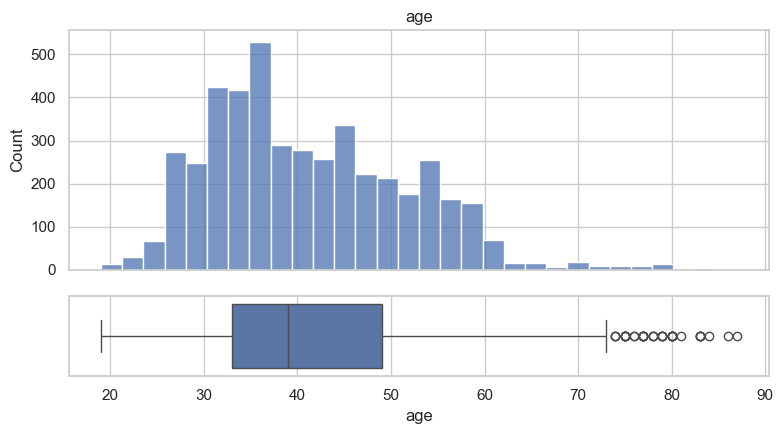

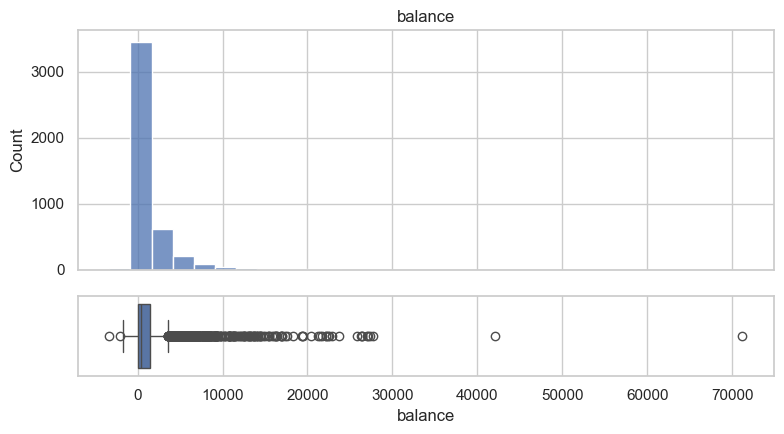

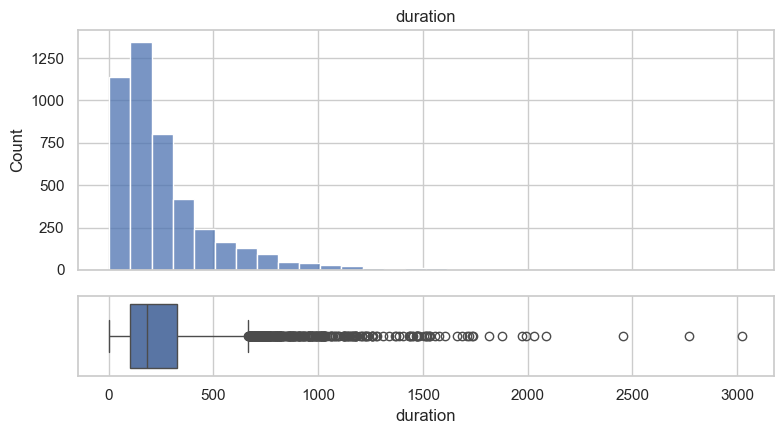

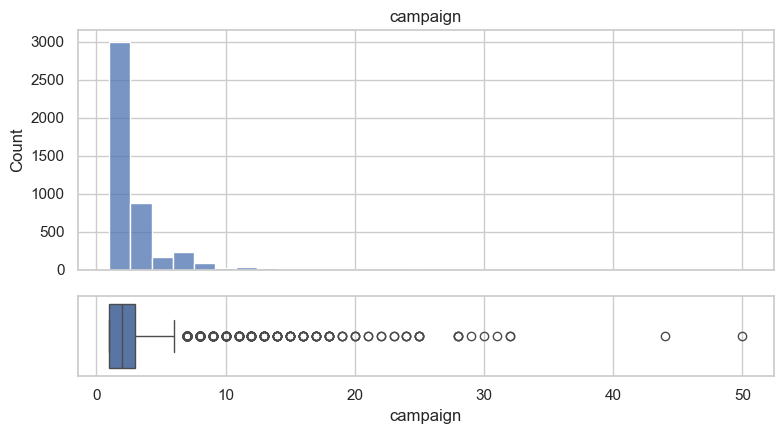

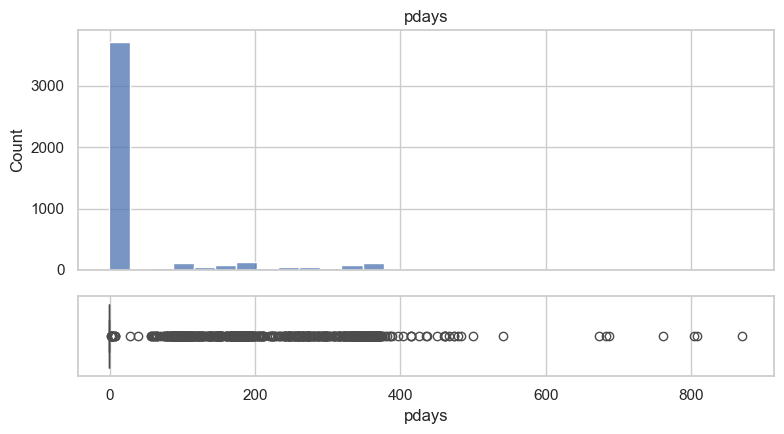

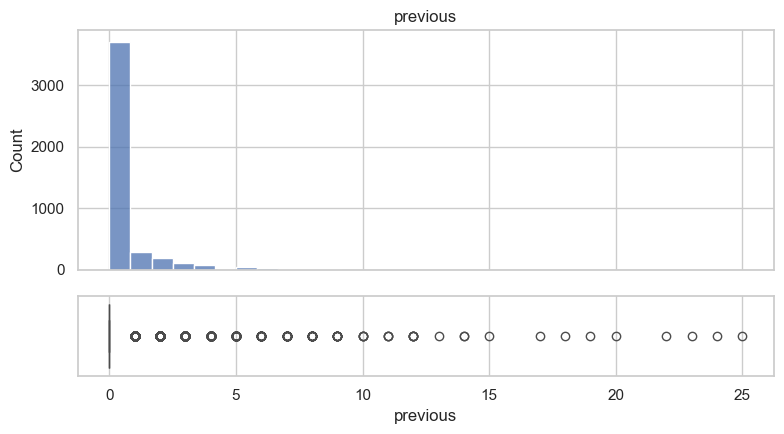

In [6]:
def plot_numerica(df, var, bins=30):
    """Histograma com boxplot logo abaixo, no mesmo eixo x."""
    fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True,
                                         gridspec_kw={'height_ratios': [3, 1]})
    sns.histplot(df[var], bins=bins, ax=ax_hist)
    sns.boxplot(x=df[var], ax=ax_box)
    ax_hist.set_title(var)
    plt.tight_layout()
    plt.show()


for var in ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']:
    plot_numerica(bank, var)

- **`age`:** os clientes se concentram predominantemente entre 30 e 50 anos; os clientes mais velhos aparecem como outliers.
- **`balance`:** distribuição muito assimétrica, com cauda longa à direita e alguns saldos negativos. A média é bem maior que a mediana, puxada pelos saldos altos.
- **`duration`:** também assimétrica à direita (valores em **segundos**).
- **`campaign`:** a quantidade de contatos se concentra fortemente em até 10, mas há casos isolados com 20, 30 e até mais de 40 contatos na mesma campanha. Vale a pena questionar se são erros de registro.
- **`pdays` e `previous`:** a grande maioria dos clientes tem `pdays = -1` e `previous = 0`, ou seja, nunca havia sido contatada antes. Essas variáveis são examinadas na seção 3.5.

### 2.2 Variáveis categóricas

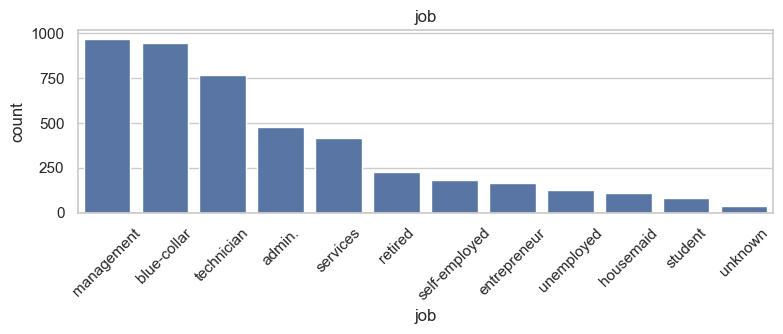

,n,%
job,,
management,969,21.4333
blue-collar,946,20.9246
technician,768,16.9874
admin.,478,10.5729
services,417,9.2236
retired,230,5.0874
self-employed,183,4.0478
entrepreneur,168,3.7160
unemployed,128,2.8312


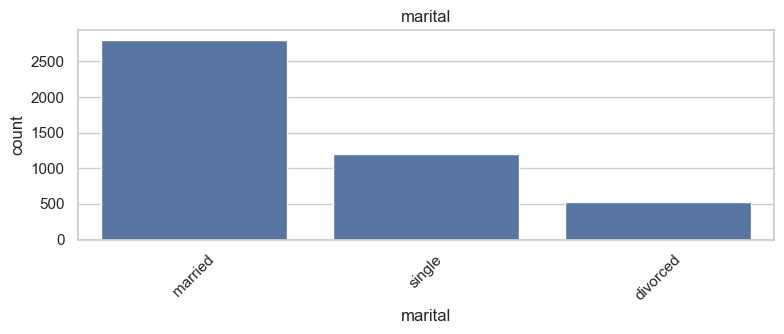

,n,%
marital,,
married,2797,61.8668
single,1196,26.4543
divorced,528,11.6788


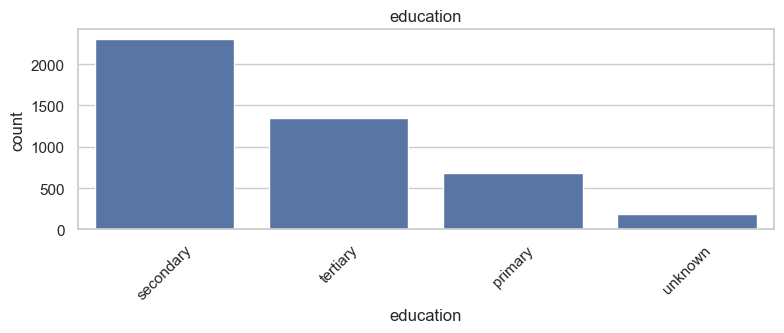

,n,%
education,,
secondary,2306,51.0064
tertiary,1350,29.8607
primary,678,14.9967
unknown,187,4.1363


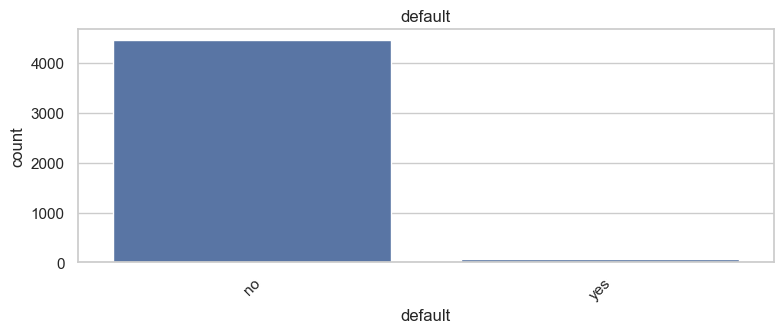

,n,%
default,,
no,4445,98.3190
yes,76,1.6810


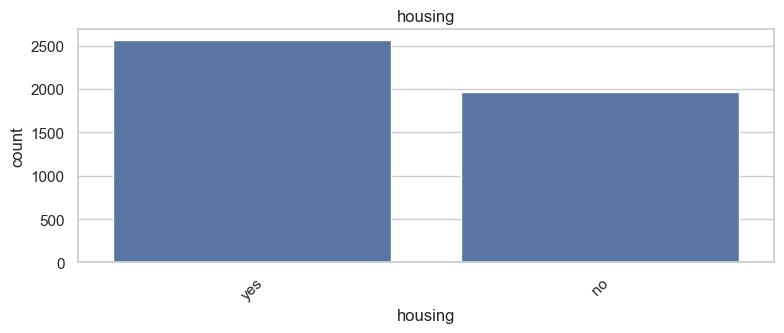

,n,%
housing,,
yes,2559,56.6025
no,1962,43.3975


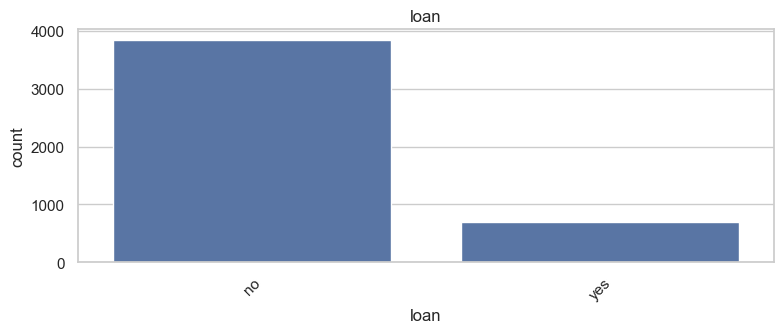

,n,%
loan,,
no,3830,84.7158
yes,691,15.2842


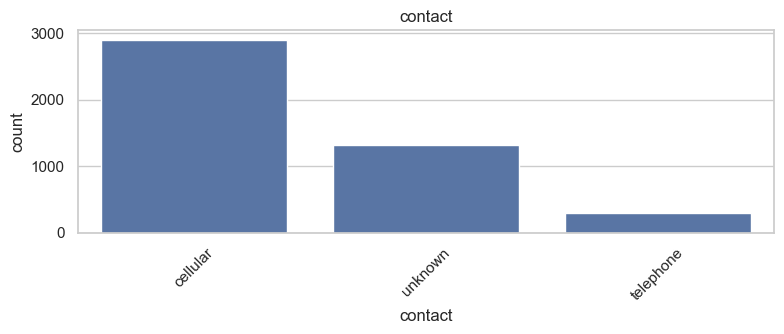

,n,%
contact,,
cellular,2896,64.0566
unknown,1324,29.2856
telephone,301,6.6578


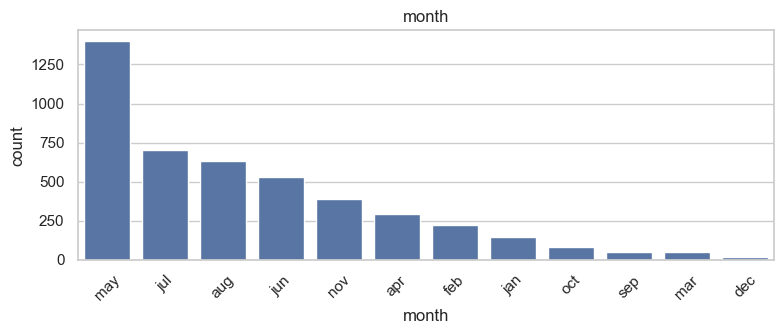

,n,%
month,,
may,1398,30.9224
jul,706,15.6160
aug,633,14.0013
jun,531,11.7452
nov,389,8.6043
apr,293,6.4809
feb,222,4.9104
jan,148,3.2736
oct,80,1.7695


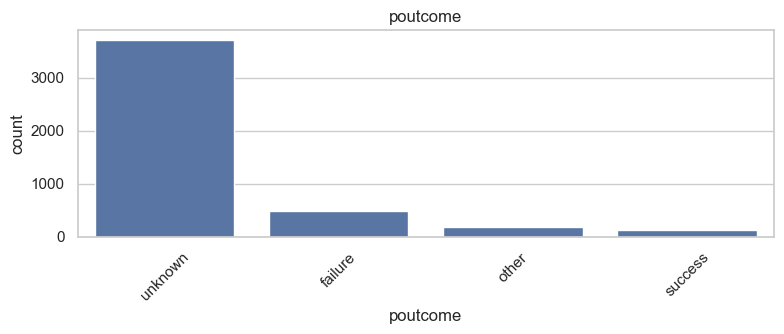

,n,%
poutcome,,
unknown,3705,81.9509
failure,490,10.8383
other,197,4.3574
success,129,2.8534


In [7]:
def frequencias(df, var):
    tab = df[var].value_counts().to_frame('n')
    tab['%'] = tab['n'] / tab['n'].sum() * 100
    return tab


def plot_categorica(df, var):
    ordem = df[var].value_counts().index
    fig, ax = plt.subplots(figsize=(8, 3.5))
    sns.countplot(data=df, x=var, order=ordem, ax=ax)
    ax.tick_params(axis='x', rotation=45)
    ax.set_title(var)
    plt.tight_layout()
    plt.show()
    display(frequencias(df, var))


for var in CATEGORICAS:
    plot_categorica(bank, var)

- **`job`:** os clientes mais frequentes têm ocupações de gerência (`management`), operárias (`blue-collar`) ou técnicas (`technician`). Juntas, essas três categorias somam quase 60% da base.
- **`marital`:** mais de 61% dos clientes são casados, seguidos pelos solteiros, com cerca de 26%.
- **`education`:** mais de 50% têm ensino secundário, cerca de 30% têm ensino terciário, cerca de 15% têm apenas o primário e em cerca de 4% a escolaridade é desconhecida.
- **`default`:** quase 99% dos clientes não têm crédito em default. Isso indica um bom perfil de pagamento, mas também que a variável varia pouco e, portanto, deve trazer pouca informação ao modelo.
- **`housing`:** mais de 56% dos clientes têm crédito habitacional.
- **`loan`:** mais de 84% dos clientes não têm empréstimo pessoal. A relação com `housing` é verificada na seção 3.4.
- **`contact`:** a maior parte dos contatos (cerca de 64%) foi feita pelo celular do cliente.
- **`month`:** maio concentra cerca de 30% dos últimos contatos com os clientes.
- **`poutcome`:** a categoria `unknown` domina, já que a maioria dos clientes não participou de campanhas anteriores.

### 2.3 Variável resposta

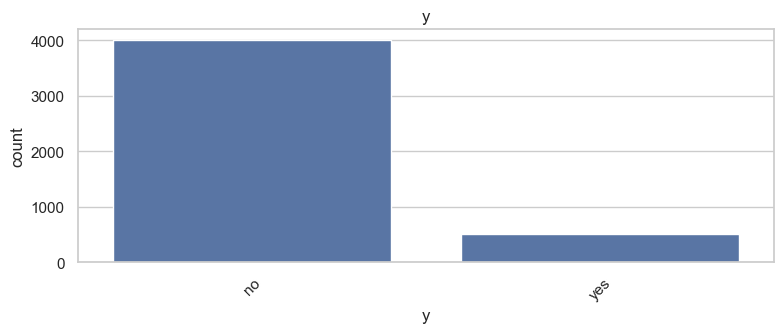

,n,%
y,,
no,4000,88.4760
yes,521,11.5240


In [8]:
plot_categorica(bank, ALVO)

Mais de 88% dos clientes **não** subscreveram o depósito: a base é fortemente desbalanceada. Isso tem três consequências práticas:

1. A acurácia sozinha engana: um modelo que responde sempre "não" já acerta cerca de 88%.
2. Pontos de corte como 0,5 tendem a classificar quase todo mundo como "não"; cortes mais baixos precisam ser avaliados.
3. A separação treino/teste deve ser **estratificada** para manter a mesma proporção de eventos nas duas bases.

## 3. Análise bivariada

### 3.1 Variáveis numéricas × `y`

Como as distribuições não são normais, as medianas dos dois grupos são comparadas pelo teste não paramétrico de Mann-Whitney (o `wilcox.test` do R):

- H0: a distribuição da variável é a mesma para quem subscreveu e para quem não subscreveu
- H1: as distribuições são diferentes

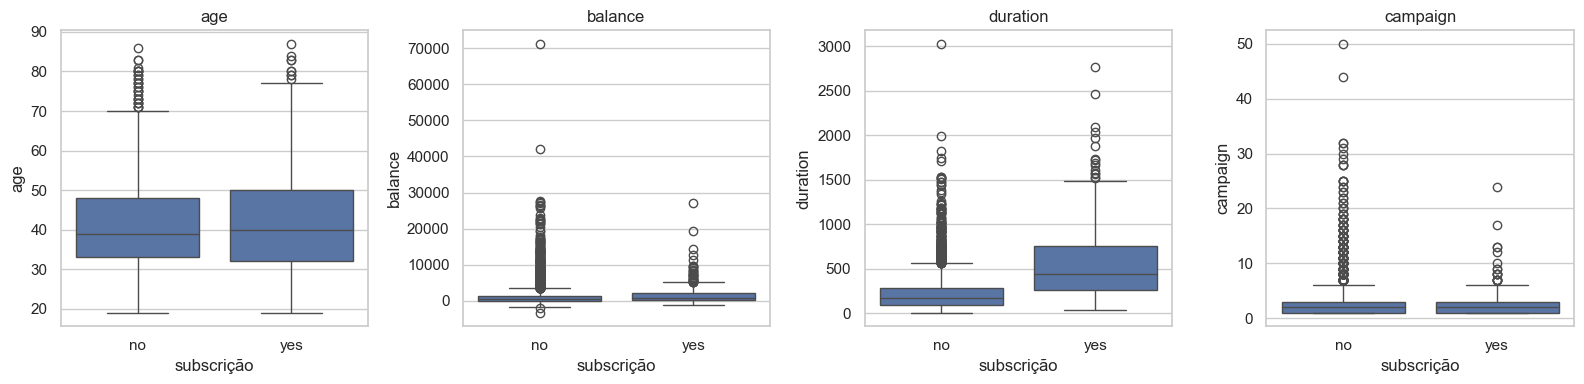

In [9]:
VARS_BIVARIADA = ['age', 'balance', 'duration', 'campaign']

fig, axes = plt.subplots(1, len(VARS_BIVARIADA), figsize=(16, 4))
for ax, var in zip(axes, VARS_BIVARIADA):
    sns.boxplot(data=bank, x=ALVO, y=var, ax=ax)
    ax.set(xlabel='subscrição', title=var)
plt.tight_layout()
plt.show()

In [10]:
def teste_mann_whitney(df, variaveis, alvo=ALVO):
    linhas = []
    for var in variaveis:
        sim = df.loc[df[alvo] == 'yes', var]
        nao = df.loc[df[alvo] == 'no', var]
        teste = stats.mannwhitneyu(sim, nao, alternative='two-sided', method='asymptotic')
        linhas.append({'variavel': var, 'mediana_yes': sim.median(),
                       'mediana_no': nao.median(), 'p_valor': teste.pvalue})
    return pd.DataFrame(linhas).sort_values('p_valor')


teste_mann_whitney(bank, VARS_BIVARIADA)

,variavel,mediana_yes,mediana_no,p_valor
2,duration,442.0000,167.0000,0.0000
1,balance,710.0000,419.5000,0.0000
3,campaign,2.0000,2.0000,0.0000
0,age,40.0000,39.0000,0.2740


**Como ler:** p-valor < 0,05 indica evidência de que os grupos diferem. Um p-valor > 0,05 **não prova** que os grupos são iguais; significa apenas que os dados não trazem evidência suficiente de diferença.

- **`duration`** é a variável que mais separa os grupos: ligações de quem subscreveu são bem mais longas. Mas, como explicado no início, ela não está disponível antes da ligação.
- **`balance`:** no boxplot a diferença parece pequena, mas o teste indica que o saldo de quem subscreve tende a ser diferente do saldo de quem não subscreve.
- **`age`:** no trabalho original, o teste não indicou diferença entre as medianas. Mesmo assim, a idade pode ter uma relação **não linear** com `y` (por exemplo, jovens e idosos mais propensos), que um teste de medianas não capta. Isso é verificado a seguir.

### 3.2 Linearidade com o logito

A regressão logística assume que uma variável numérica tem relação **linear com o logito** de P(y = yes). Para verificar isso, a variável é dividida em 10 faixas com o mesmo número de clientes e o logito observado de cada faixa é plotado contra o valor médio da variável na faixa. Se os pontos formam aproximadamente uma reta, a variável pode entrar no modelo como numérica; caso contrário, é melhor categorizá-la.

Duas mudanças em relação à versão em R:
- Lá, o gráfico mostrava a *proporção* de `y` contra o *número do percentil*, o que não verifica a linearidade com o logito.
- Lá eram 30 faixas. Com cerca de 520 eventos, 30 faixas ficam com poucos eventos cada, e algumas sem nenhum, o que gera logito infinito. Por isso aqui são 10 faixas, e o logito usa uma correção de +0,5.

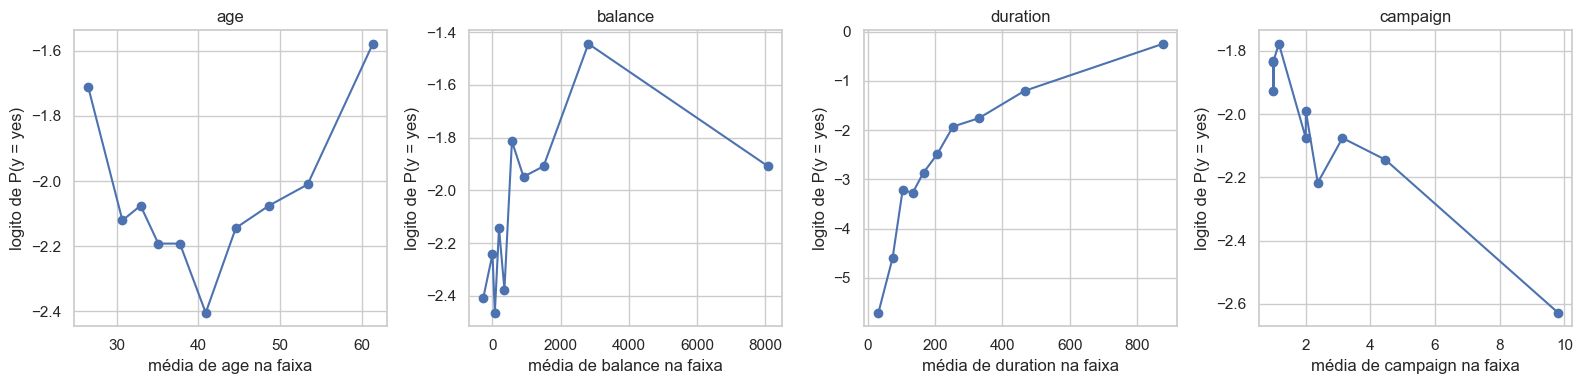

In [11]:
def logito_por_faixa(df, var, n_faixas=10, alvo=ALVO):
    # rank(method='first') reparte os empates entre faixas, como o ntile() do R
    faixa = pd.qcut(df[var].rank(method='first'), n_faixas, labels=False) + 1
    evento = (df[alvo] == 'yes').astype(int)
    tab = (pd.DataFrame({'faixa': faixa, var: df[var], 'evento': evento})
           .groupby('faixa')
           .agg(minimo=(var, 'min'), media=(var, 'mean'),
                n=('evento', 'size'), eventos=('evento', 'sum')))
    tab['taxa'] = tab['eventos'] / tab['n']
    # correção empírica (+0,5) evita logito infinito quando a faixa não tem eventos
    tab['logito'] = np.log((tab['eventos'] + 0.5) / (tab['n'] - tab['eventos'] + 0.5))
    return tab


fig, axes = plt.subplots(1, len(VARS_BIVARIADA), figsize=(16, 4))
for ax, var in zip(axes, VARS_BIVARIADA):
    tab = logito_por_faixa(bank, var)
    ax.plot(tab['media'], tab['logito'], marker='o')
    ax.set(title=var, xlabel=f'média de {var} na faixa', ylabel='logito de P(y = yes)')
plt.tight_layout()
plt.show()

In [12]:
logito_por_faixa(bank, 'campaign')

,minimo,media,n,eventos,taxa,logito
faixa,,,,,,
1,1,1.0000,453,62,0.1369,-1.8348
2,1,1.0000,452,57,0.1261,-1.9284
3,1,1.0000,452,62,0.1372,-1.8323
4,1,1.1659,452,65,0.1438,-1.7777
5,2,2.0000,452,50,0.1106,-2.0757
6,2,2.0000,452,54,0.1195,-1.9895
7,2,2.3695,452,44,0.0973,-2.2170
8,3,3.1350,452,50,0.1106,-2.0757
9,4,4.4624,452,47,0.1040,-2.1444


**Decisões a partir dos gráficos:**

- **`age`** e **`balance`**: se a relação com o logito não é uma reta (curva em U, patamares), elas entram no modelo **categorizadas** em faixas.
- **`campaign`**: a tendência é de queda (quanto mais contatos, menor a chance de subscrição), aproximadamente monotônica. Ela entra como **numérica**.
- **`duration`**: a relação com o logito é crescente e forte, mas ela só entra no modelo de referência.

### 3.3 Variáveis categóricas × `y`

A associação entre cada variável categórica e `y` é medida pelo teste qui-quadrado e pelo **V de Cramér**. O V vai de 0 (nenhuma associação) a 1 (associação perfeita); como referência, valores perto de 0,1 indicam associação fraca, perto de 0,3 moderada e acima de 0,5 forte.

In [13]:
def ranking_associacao(df, variaveis, alvo=ALVO):
    linhas = []
    for var in variaveis:
        tabela = pd.crosstab(df[var], df[alvo]).to_numpy()
        _, p_valor, _, _ = stats.chi2_contingency(tabela)
        linhas.append({'variavel': var, 'chi2_p_valor': p_valor,
                       'v_cramer': association(tabela, method='cramer')})
    return pd.DataFrame(linhas).sort_values('v_cramer', ascending=False)


ranking_associacao(bank, CATEGORICAS)

,variavel,chi2_p_valor,v_cramer
8,poutcome,0.0000,0.2925
7,month,0.0000,0.2354
6,contact,0.0000,0.1394
0,job,0.0000,0.1235
4,housing,0.0000,0.1047
5,loan,0.0000,0.0705
1,marital,0.0001,0.0649
2,education,0.0016,0.0581
3,default,1.0000,0.0013


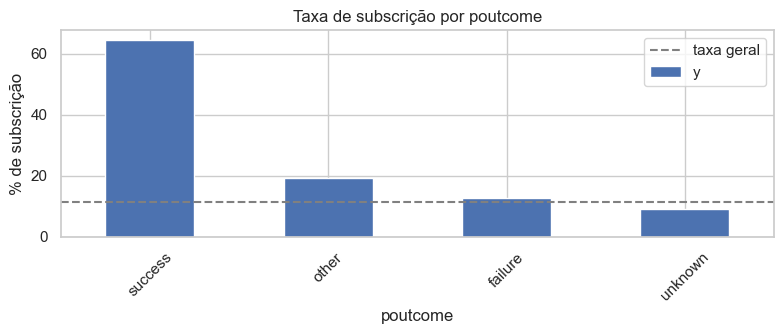

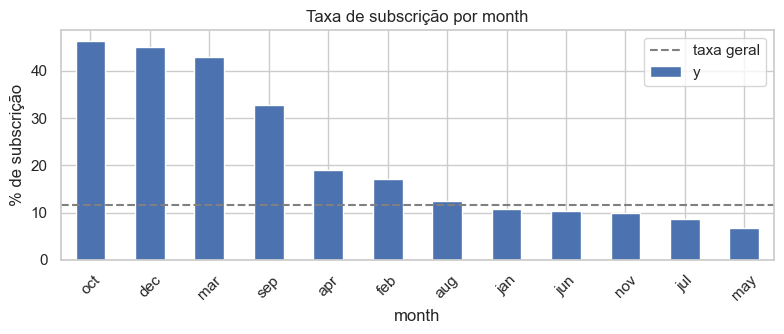

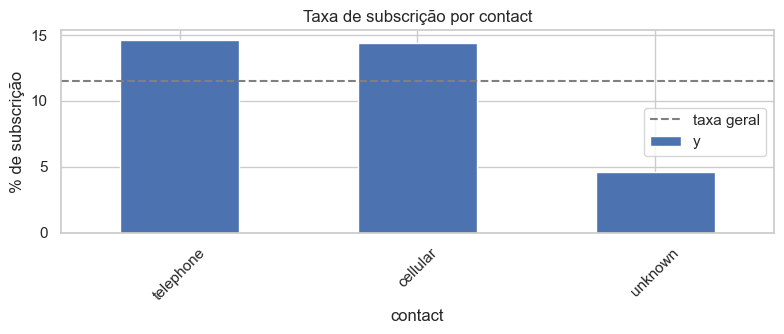

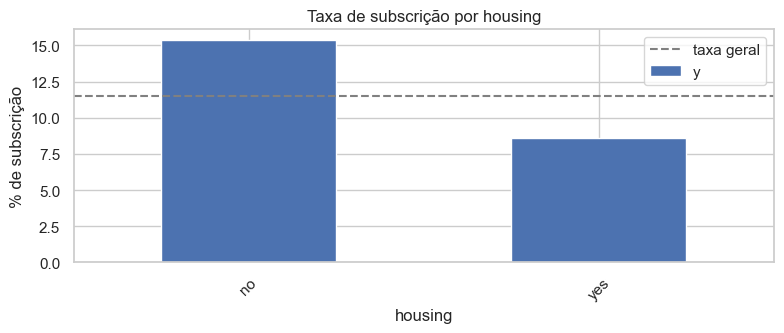

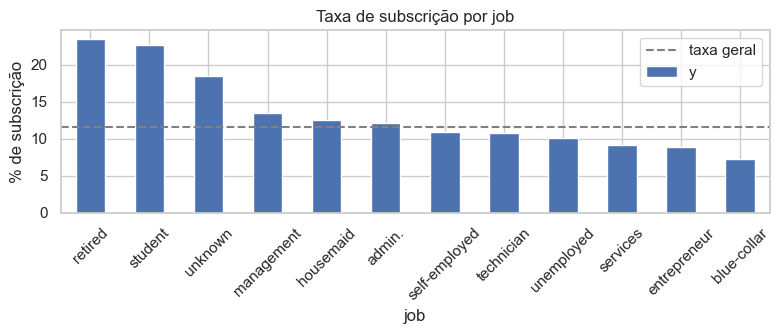

In [14]:
def plot_taxa_por_categoria(df, var, alvo=ALVO):
    evento = df[alvo] == 'yes'
    taxa = evento.groupby(df[var]).mean().sort_values(ascending=False) * 100
    fig, ax = plt.subplots(figsize=(8, 3.5))
    taxa.plot.bar(ax=ax)
    ax.axhline(evento.mean() * 100, color='gray', linestyle='--', label='taxa geral')
    ax.set(ylabel='% de subscrição', xlabel=var, title=f'Taxa de subscrição por {var}')
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
    plt.tight_layout()
    plt.show()


for var in ['poutcome', 'month', 'contact', 'housing', 'job']:
    plot_taxa_por_categoria(bank, var)

O ranking indica quais variáveis categóricas têm maior potencial explicativo. Os gráficos de taxa mostram **em que direção** cada categoria se afasta da taxa geral, o que ajuda a decidir como agrupar categorias na seção 4. Por exemplo, clientes cujo resultado da campanha anterior foi sucesso (`poutcome = success`) têm taxa de subscrição muito acima da média.

### 3.4 Crédito habitacional × empréstimo pessoal

Na versão em R, a análise concluía que "quem tem crédito habitacional não tem crédito pessoal" olhando cada variável separadamente. Essa conclusão só pode ser tirada cruzando as duas:

In [15]:
# % de clientes com empréstimo pessoal dentro de cada grupo de crédito habitacional
pd.crosstab(bank['housing'], bank['loan'], normalize='index') * 100

loan,no,yes
housing,,
no,85.4740,14.5260
yes,84.1344,15.8656


Se a proporção de `loan = yes` for parecida nos dois grupos de `housing`, as variáveis são praticamente independentes, e a afirmação original não se sustenta. Ter crédito habitacional não implica ausência de empréstimo pessoal.

### 3.5 `pdays`, `previous` e `poutcome`

As três variáveis descrevem o histórico de campanhas anteriores. A suspeita é que elas carregam a mesma informação:

In [16]:
nunca_contatado = bank['pdays'] == -1
print('pdays = -1 equivale a previous = 0?', nunca_contatado.equals(bank['previous'] == 0))
pd.crosstab(bank['poutcome'], nunca_contatado.rename('nunca_contatado'), margins=True)

pdays = -1 equivale a previous = 0? True


nunca_contatado,False,True,All
poutcome,,,
failure,490,0,490
other,197,0,197
success,129,0,129
unknown,0,3705,3705
All,816,3705,4521


`pdays = -1`, `previous = 0` e `poutcome = unknown` identificam essencialmente o mesmo grupo: os clientes nunca contatados antes. Como a maior parte da base está nesse grupo, `pdays` e `previous` ficam concentradas num único valor, e o que elas têm de mais útil (se houve contato anterior e qual foi o resultado) já está em `poutcome`. Por isso **`pdays` e `previous` são removidas**, e `poutcome` é mantida.

## 4. Separação treino/teste e preparação das variáveis

Na versão em R, o modelo era ajustado e avaliado na mesma base, o que torna as métricas otimistas. Aqui a base é dividida em **70% treino / 30% teste**, de forma estratificada por `y`. Tudo que é "aprendido" dos dados (o corte da mediana de `balance`, as categorias de referência das dummies, os coeficientes e o ponto de corte) usa **somente o treino**.

In [17]:
treino, teste = train_test_split(bank, test_size=TEST_SIZE, stratify=bank[ALVO],
                                 random_state=RANDOM_STATE)
treino = treino.reset_index(drop=True)
teste = teste.reset_index(drop=True)

pd.DataFrame({'n': [len(treino), len(teste)],
              '% yes': [(treino[ALVO] == 'yes').mean() * 100, (teste[ALVO] == 'yes').mean() * 100]},
             index=['treino', 'teste'])

,n,% yes
treino,3164,11.5360
teste,1357,11.4959


**Transformações** (mesmas ideias da versão em R, com rótulos corrigidos):

| Variável | Transformação |
|---|---|
| `age` | 3 faixas: `<35`, `35-54`, `55+` |
| `balance` | 2 faixas pela **mediana do treino** (o 444 usado no R era a mediana da base completa) |
| `day` | 2 faixas: `1-19` e `20-31` (no R os rótulos diziam "1-20", mas o dia 20 caía na segunda faixa) |
| `job` | `management`, `blue-collar`, `technician` e `others` |
| `month` | semestre: `S1` (jan–jun) e `S2` (jul–dez) |
| `campaign`, `duration` | numéricas |
| demais categóricas | mantidas como estão |

Cada categórica vira dummies, e a **categoria mais frequente no treino** fica como referência (equivalente a `remove_most_frequent_dummy = TRUE` do `fastDummies`).

In [18]:
JOBS_PRINCIPAIS = ['management', 'blue-collar', 'technician']
MESES_S1 = ['jan', 'feb', 'mar', 'apr', 'may', 'jun']

VARS_NUMERICAS_MODELO = ['campaign', 'duration']
VARS_CATEGORICAS_MODELO = ['age_range', 'balance_range', 'day_range', 'job', 'semester',
                           'marital', 'education', 'contact', 'default', 'housing',
                           'loan', 'poutcome']


def criar_variaveis(df, corte_balance):
    base = pd.DataFrame(index=df.index)
    base['age_range'] = pd.cut(df['age'], bins=[0, 35, 55, np.inf], right=False,
                               labels=['<35', '35-54', '55+']).astype(str)
    base['balance_range'] = np.where(df['balance'] >= corte_balance,
                                     'acima_mediana', 'abaixo_mediana')
    base['day_range'] = np.where(df['day'] < 20, '1-19', '20-31')
    base['job'] = df['job'].where(df['job'].isin(JOBS_PRINCIPAIS), 'others')
    base['semester'] = np.where(df['month'].isin(MESES_S1), 'S1', 'S2')
    for var in ['marital', 'education', 'contact', 'default', 'housing', 'loan', 'poutcome']:
        base[var] = df[var]
    for var in VARS_NUMERICAS_MODELO:
        base[var] = df[var]
    return base


def criar_dummies(base, colunas_dummies=None):
    """Gera as dummies. Sem colunas_dummies, descarta a categoria mais frequente
    de cada variável (a referência); com elas, reaproduz as mesmas colunas do treino."""
    dummies = pd.get_dummies(base[VARS_CATEGORICAS_MODELO], dtype=float)
    if colunas_dummies is None:
        referencias = [f'{var}_{base[var].value_counts().idxmax()}'
                       for var in VARS_CATEGORICAS_MODELO]
        colunas_dummies = [c for c in dummies.columns if c not in referencias]
    dummies = dummies.reindex(columns=colunas_dummies, fill_value=0.0)
    return pd.concat([base[VARS_NUMERICAS_MODELO].astype(float), dummies], axis=1), colunas_dummies

In [19]:
corte_balance = treino['balance'].median()
print('Mediana de balance no treino:', corte_balance)

base_treino = criar_variaveis(treino, corte_balance)
base_teste = criar_variaveis(teste, corte_balance)

X_treino_full, colunas_dummies = criar_dummies(base_treino)
X_teste_full, _ = criar_dummies(base_teste, colunas_dummies)
y_treino = (treino[ALVO] == 'yes').astype(int)
y_teste = (teste[ALVO] == 'yes').astype(int)

# Modelos principais: sem duration
X_treino = X_treino_full.drop(columns='duration')
X_teste = X_teste_full.drop(columns='duration')

print('Categorias de referência:')
for var in VARS_CATEGORICAS_MODELO:
    print(f'  {var}: {base_treino[var].value_counts().idxmax()}')
print('Variáveis candidatas:', X_treino.shape[1])

Mediana de balance no treino: 452.0
Categorias de referência:
  age_range: 35-54
  balance_range: acima_mediana
  day_range: 1-19
  job: others
  semester: S1
  marital: married
  education: secondary
  contact: cellular
  default: no
  housing: yes
  loan: no
  poutcome: unknown
Variáveis candidatas: 22


## 5. Estimação e seleção dos modelos

Primeiro é estimada a regressão logística com todas as variáveis candidatas. Em seguida, dois modelos reduzidos são obtidos por **stepwise bidirecional** (a cada passo, testa retirar cada variável do modelo e incluir cada variável de fora, e aplica a mudança que mais reduz o critério):

- **Stepwise AIC:** critério = −2·log-verossimilhança + 2·(nº de parâmetros).
- **Stepwise p-valor:** mesma conta, com penalidade 3,84 por parâmetro em vez de 2. Esse valor é o quantil 95% da qui-quadrado com 1 grau de liberdade, então uma variável só fica no modelo se o teste da razão de verossimilhança for significativo a 5%. É o equivalente ao `step(modelo, k = 3.841459)` do R.

O `statsmodels` não tem uma função de stepwise, então ela é implementada abaixo seguindo a mesma lógica do `step()` do R.

In [20]:
def ajustar_logit(X, y, variaveis):
    exog = sm.add_constant(X[list(variaveis)], has_constant='add')
    return sm.GLM(y, exog, family=sm.families.Binomial()).fit()


def criterio(modelo, k):
    n_parametros = modelo.df_model + 1  # + intercepto
    return -2 * modelo.llf + k * n_parametros


def stepwise(X, y, k=2.0, verbose=True):
    """Stepwise bidirecional partindo do modelo completo, como o step() do R."""
    selecionadas = list(X.columns)
    melhor = criterio(ajustar_logit(X, y, selecionadas), k)
    if verbose:
        print(f'{"modelo completo":<35} critério = {melhor:.2f}')
    while True:
        candidatos = []
        for var in selecionadas:
            variaveis = [v for v in selecionadas if v != var]
            candidatos.append((criterio(ajustar_logit(X, y, variaveis), k), f'- {var}', variaveis))
        for var in X.columns.difference(selecionadas):
            variaveis = selecionadas + [var]
            candidatos.append((criterio(ajustar_logit(X, y, variaveis), k), f'+ {var}', variaveis))
        valor, passo, variaveis = min(candidatos, key=lambda c: c[0])
        if valor >= melhor:
            break
        melhor, selecionadas = valor, variaveis
        if verbose:
            print(f'{passo:<35} critério = {valor:.2f}')
    return ajustar_logit(X, y, selecionadas)


def prever(modelo, X):
    variaveis = modelo.model.exog_names[1:]  # sem a constante
    return modelo.predict(sm.add_constant(X[variaveis], has_constant='add'))

In [21]:
modelo_completo = ajustar_logit(X_treino, y_treino, X_treino.columns)
modelo_completo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                 3164
Model:                            GLM   Df Residuals:                     3141
Model Family:                Binomial   Df Model:                           22
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -980.64
Date:                Tue, 13 Oct 2026   Deviance:                       1961.3
Time:                        21:32:37   Pearson chi2:                 3.22e+03
No. Iterations:                     6   Pseudo R-squ. (CS):            0.09088
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -2.0486      0.206     -9.949      0.000      -2.452      -1.645
campaign                        -0.0720      0.030     -2.411      0.016      -0.130      -0.013
age_range_55+                    0.3249      0.184      1.767      0.077      -0.036       0.685
age_range_<35                    0.2225      0.146      1.521      0.128      -0.064       0.509
balance_range_abaixo_mediana    -0.3247      0.124     -2.615      0.009      -0.568      -0.081
day_range_20-31                 -0.1045      0.131     -0.796      0.426      -0.362       0.153
job_blue-collar                 -0.3548      0.198     -1.789      0.074      -0.743       0.034
job_management                   0.1062      0.179      0.592      0.554      -0.246       0.458
job_technician                  -0.2277      0.176     -1.293      0.196      -0.573       0.117
semester_S2                      0.0539      0.138      0.389      0.697      -0.218       0.325
marital_divorced                 0.5543      0.174      3.186      0.001       0.213       0.895
marital_single                   0.2444      0.152      1.611      0.107      -0.053       0.542
education_primary                0.0091      0.201      0.045      0.964      -0.385       0.403
education_tertiary              -0.0395      0.165     -0.240      0.810      -0.362       0.283
education_unknown               -0.3801      0.330     -1.151      0.250      -1.027       0.267
contact_telephone                0.1041      0.220      0.473      0.637      -0.328       0.536
contact_unknown                 -0.8758      0.200     -4.377      0.000      -1.268      -0.484
default_yes                      0.6219      0.402      1.547      0.122      -0.166       1.410
housing_no                       0.4076      0.130      3.132      0.002       0.153       0.663
loan_yes                        -0.5890      0.201     -2.927      0.003      -0.983      -0.195
poutcome_failure                 0.1350      0.189      0.715      0.475      -0.235       0.505
poutcome_other                   0.5759      0.237      2.430      0.015       0.111       1.040
poutcome_success                 2.6777      0.245     10.919      0.000       2.197       3.158
================================================================================================
"""

In [22]:
K_PVALOR = stats.chi2.ppf(0.95, df=1)  # 3.8415

print('=== Stepwise AIC ===')
modelo_aic = stepwise(X_treino, y_treino, k=2)
print()
print('=== Stepwise p-valor ===')
modelo_pv = stepwise(X_treino, y_treino, k=K_PVALOR)

# Modelo de referência: mesmo procedimento, mas com duration entre as candidatas
modelo_duration = stepwise(X_treino_full, y_treino, k=2, verbose=False)

MODELOS = {
    'Stepwise AIC': modelo_aic,
    'Stepwise P-valor': modelo_pv,
    'AIC com duration (referência)': modelo_duration,
}

=== Stepwise AIC ===
modelo completo                     critério = 2007.28
- education_primary                 critério = 2005.29
- education_tertiary                critério = 2003.35
- semester_S2                       critério = 2001.50
- contact_telephone                 critério = 1999.72
- job_management                    critério = 1998.01
- poutcome_failure                  critério = 1996.42
- day_range_20-31                   critério = 1995.00
- education_unknown                 critério = 1994.49

=== Stepwise p-valor ===
modelo completo                     critério = 2049.64
- education_primary                 critério = 2045.80
- education_tertiary                critério = 2042.02
- semester_S2                       critério = 2038.33
- contact_telephone                 critério = 2034.71
- job_management                    critério = 2031.16
- poutcome_failure                  critério = 2027.73
- day_range_20-31                   critério = 2024.47
- education_unknow

In [23]:
# Variáveis selecionadas por modelo
pd.DataFrame({nome: pd.Series(1, index=modelo.model.exog_names[1:])
              for nome, modelo in MODELOS.items()}).notna()

,Stepwise AIC,Stepwise P-valor,AIC com duration (referência)
age_range_55+,True,False,False
age_range_<35,True,False,True
balance_range_abaixo_mediana,True,True,True
campaign,True,True,True
contact_unknown,True,True,True
default_yes,True,False,True
duration,False,False,True
education_unknown,False,False,True
housing_no,True,True,True
job_blue-collar,True,True,True


In [24]:
def tabela_odds(modelo):
    ic = modelo.conf_int()
    return pd.DataFrame({
        'coef': modelo.params,
        'odds_ratio': np.exp(modelo.params),
        'ic_2.5%': np.exp(ic[0]),
        'ic_97.5%': np.exp(ic[1]),
        'p_valor': modelo.pvalues,
    })


print('=== Stepwise AIC ===')
display(tabela_odds(modelo_aic))
print('=== Stepwise P-valor ===')
display(tabela_odds(modelo_pv))

=== Stepwise AIC ===


,coef,odds_ratio,ic_2.5%,ic_97.5%,p_valor
const,-1.9805,0.1380,0.1005,0.1894,0.0000
campaign,-0.0748,0.9279,0.8765,0.9823,0.0101
age_range_55+,0.3252,1.3843,0.9767,1.9619,0.0676
age_range_<35,0.2125,1.2367,0.9312,1.6424,0.1421
balance_range_abaixo_mediana,-0.3332,0.7167,0.5627,0.9127,0.0069
job_blue-collar,-0.3789,0.6846,0.4797,0.9770,0.0368
job_technician,-0.2612,0.7701,0.5582,1.0626,0.1118
marital_divorced,0.5490,1.7316,1.2327,2.4324,0.0015
marital_single,0.2388,1.2698,0.9452,1.7058,0.1128
contact_unknown,-0.9481,0.3875,0.2722,0.5516,0.0000


=== Stepwise P-valor ===


,coef,odds_ratio,ic_2.5%,ic_97.5%,p_valor
const,-1.8250,0.1612,0.1230,0.2113,0.0000
campaign,-0.0792,0.9238,0.8721,0.9786,0.0070
balance_range_abaixo_mediana,-0.3143,0.7303,0.5762,0.9257,0.0094
job_blue-collar,-0.3606,0.6973,0.4924,0.9874,0.0422
marital_divorced,0.4687,1.5978,1.1579,2.2049,0.0043
contact_unknown,-0.9745,0.3774,0.2654,0.5365,0.0000
housing_no,0.4174,1.5180,1.1922,1.9328,0.0007
loan_yes,-0.5801,0.5599,0.3789,0.8274,0.0036
poutcome_other,0.5844,1.7940,1.1459,2.8085,0.0106
poutcome_success,2.5785,13.1779,8.2651,21.0109,0.0000


**Como ler as odds ratios:** para uma dummy, a odds ratio compara a chance de subscrição da categoria com a da categoria de referência, mantendo as demais variáveis fixas. Por exemplo, uma odds ratio de 2 significa o dobro da chance, e uma de 0,5, metade. Para `campaign`, a odds ratio é o efeito de **um contato a mais**; um valor abaixo de 1 indica que insistir com o mesmo cliente reduz a chance de subscrição.

### 5.1 Multicolinearidade (VIF)

Um VIF acima de 5 (ou, num critério mais tolerante, acima de 10) indica que a variável é bem explicada pelas outras, o que deixa os coeficientes instáveis. O cálculo aqui usa a matriz de variáveis do modelo; os valores podem diferir um pouco do `car::vif()` do R, que usa a matriz de covariância dos coeficientes.

In [25]:
def calcular_vif(modelo):
    exog = modelo.model.exog
    nomes = modelo.model.exog_names
    vifs = [variance_inflation_factor(exog, i) for i in range(1, exog.shape[1])]  # pula a constante
    return pd.Series(vifs, index=nomes[1:], name='VIF').sort_values(ascending=False)


pd.concat({'Stepwise AIC': calcular_vif(modelo_aic),
           'Stepwise P-valor': calcular_vif(modelo_pv)}, axis=1)

,Stepwise AIC,Stepwise P-valor
marital_single,1.2634,NaN
age_range_<35,1.2562,NaN
job_blue-collar,1.1362,1.0610
age_range_55+,1.1333,NaN
housing_no,1.1234,1.0829
contact_unknown,1.0985,1.0930
job_technician,1.0753,NaN
marital_divorced,1.0714,1.0073
balance_range_abaixo_mediana,1.0372,1.0153
poutcome_success,1.0306,1.0291


## 6. Avaliação dos modelos

Os modelos são comparados segundo três objetivos, sempre na **base de teste**. As métricas da base de treino aparecem ao lado para identificar overfitting: uma queda grande do treino para o teste é sinal de que o modelo decorou a base de ajuste.

### 6.1 Objetivo estimação e visão geral

- **MSE (Brier) / RMSE:** erro das probabilidades previstas em relação ao 0/1 observado (quanto menor, melhor).
- **AUC:** probabilidade de o modelo dar um score maior a um subscritor do que a um não subscritor (0,5 = aleatório; 1 = perfeito).
- **Gini** = 2·AUC − 1.
- **KS:** maior distância entre as distribuições acumuladas de score dos dois grupos. Aqui o KS é calculado de forma exata pela curva ROC, e não por decis como no R.

In [26]:
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return np.max(tpr - fpr)


def metricas_gerais(y, p):
    auc = roc_auc_score(y, p)
    brier = brier_score_loss(y, p)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks(y, p),
            'MSE (Brier)': brier, 'RMSE': np.sqrt(brier)}


linhas = []
for nome, modelo in MODELOS.items():
    for base, X, y in [('treino', X_treino_full, y_treino), ('teste', X_teste_full, y_teste)]:
        linhas.append({'modelo': nome, 'base': base, 'n_variaveis': int(modelo.df_model),
                       **metricas_gerais(y, prever(modelo, X))})
pd.DataFrame(linhas).set_index(['modelo', 'base'])

n_variaveis    AUC   Gini     KS  \
modelo                        base                                       
Stepwise AIC                  treino           14 0.7344 0.4688 0.3327   
                              teste            14 0.7048 0.4097 0.2898   
Stepwise P-valor              treino            9 0.7281 0.4563 0.3291   
                              teste             9 0.7036 0.4072 0.3074   
AIC com duration (referência) treino           14 0.8882 0.7764 0.6335   
                              teste            14 0.8697 0.7394 0.5764   

                                      MSE (Brier)   RMSE  
modelo                        base                        
Stepwise AIC                  treino       0.0885 0.2975  
                              teste        0.0933 0.3055  
Stepwise P-valor              treino       0.0890 0.2983  
                              teste        0.0930 0.3049  
AIC com duration (referência) treino       0.0732 0.2705  
                              teste        0.0797 0.2824

### 6.2 Objetivo decisão: escolha do ponto de corte

Para transformar a probabilidade numa decisão (ligar ou não para o cliente), é preciso um ponto de corte. Como só cerca de 11,5% dos clientes subscrevem, cortes como 0,5 praticamente não classificam ninguém como "sim". Por isso são avaliados cortes de 0,1 a 0,6 e também o **corte que maximiza o KS**, escolhido no treino e aplicado no teste.

- **Precision:** dos clientes que o modelo mandaria contatar, quantos de fato subscrevem.
- **Recall:** dos clientes que subscrevem, quantos o modelo encontra.
- **% acionados:** fração da base que seria contatada com aquele corte.

In [27]:
def corte_ks(y, p):
    fpr, tpr, limiares = roc_curve(y, p)
    return limiares[np.argmax(tpr - fpr)]


def metricas_decisao(y, p, cortes):
    linhas = []
    for corte in cortes:
        pred = (p >= corte).astype(int)
        linhas.append({
            'corte': corte,
            'accuracy': accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred),
            'F1': f1_score(y, pred, zero_division=0),
            '% acionados': pred.mean() * 100,
        })
    return pd.DataFrame(linhas)


CORTES_FIXOS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

tabelas = []
for nome, modelo in MODELOS.items():
    corte_otimo = corte_ks(y_treino, prever(modelo, X_treino_full))
    tab = metricas_decisao(y_teste, prever(modelo, X_teste_full), CORTES_FIXOS + [corte_otimo])
    tab.insert(0, 'modelo', nome)
    tab['corte_ks'] = tab['corte'] == corte_otimo
    tabelas.append(tab)
pd.concat(tabelas, ignore_index=True)

,modelo,corte,accuracy,precision,recall,F1,% acionados,corte_ks
0,Stepwise AIC,0.1000,0.6065,0.1786,0.6731,0.2823,43.3309,False
1,Stepwise AIC,0.2000,0.8541,0.3385,0.2821,0.3077,9.5800,False
2,Stepwise AIC,0.3000,0.8858,0.5116,0.1410,0.2211,3.1688,False
3,Stepwise AIC,0.4000,0.8880,0.5556,0.1282,0.2083,2.6529,False
4,Stepwise AIC,0.5000,0.8895,0.5882,0.1282,0.2105,2.5055,False
5,Stepwise AIC,0.6000,0.8895,0.5938,0.1218,0.2021,2.3581,False
6,Stepwise AIC,0.1123,0.6529,0.1906,0.6218,0.2917,37.5092,True
7,Stepwise P-valor,0.1000,0.6146,0.1831,0.6795,0.2884,42.6676,False
8,Stepwise P-valor,0.2000,0.8732,0.4000,0.2051,0.2712,5.8954,False
9,Stepwise P-valor,0.3000,0.8880,0.5526,0.1346,0.2165,2.8003,False


In [28]:
# Matriz de confusão do Stepwise AIC no corte de máximo KS (base de teste)
corte = corte_ks(y_treino, prever(modelo_aic, X_treino_full))
pred = (prever(modelo_aic, X_teste_full) >= corte).astype(int)
print(f'Corte: {corte:.4f}')
pd.crosstab(pd.Series(y_teste.values, name='real'),
            pd.Series(pred.values, name='previsto'), margins=True)

Corte: 0.1123


previsto,0,1,All
real,,,
0,789,412,1201
1,59,97,156
All,848,509,1357


Note como a acurácia **cai** conforme o corte diminui, enquanto o recall sobe. Num problema desbalanceado isso é esperado: a acurácia alta dos cortes altos vem de acertar os "não", que são a maioria. A escolha do corte é uma decisão de negócio que pesa o custo de cada ligação contra o ganho de cada subscrição.

### 6.3 Objetivo ordenação: lift, ganho acumulado e curva ROC

Em campanhas de marketing, o uso mais comum do modelo é **ordenar** os clientes do mais para o menos propenso e contatar apenas o topo da lista.

- **Lift do decil:** quantas vezes a taxa de subscrição do decil supera a taxa geral (1 = igual a uma escolha aleatória).
- **Ganho acumulado:** que % de todos os subscritores é capturada contatando os x% de clientes com maior score.

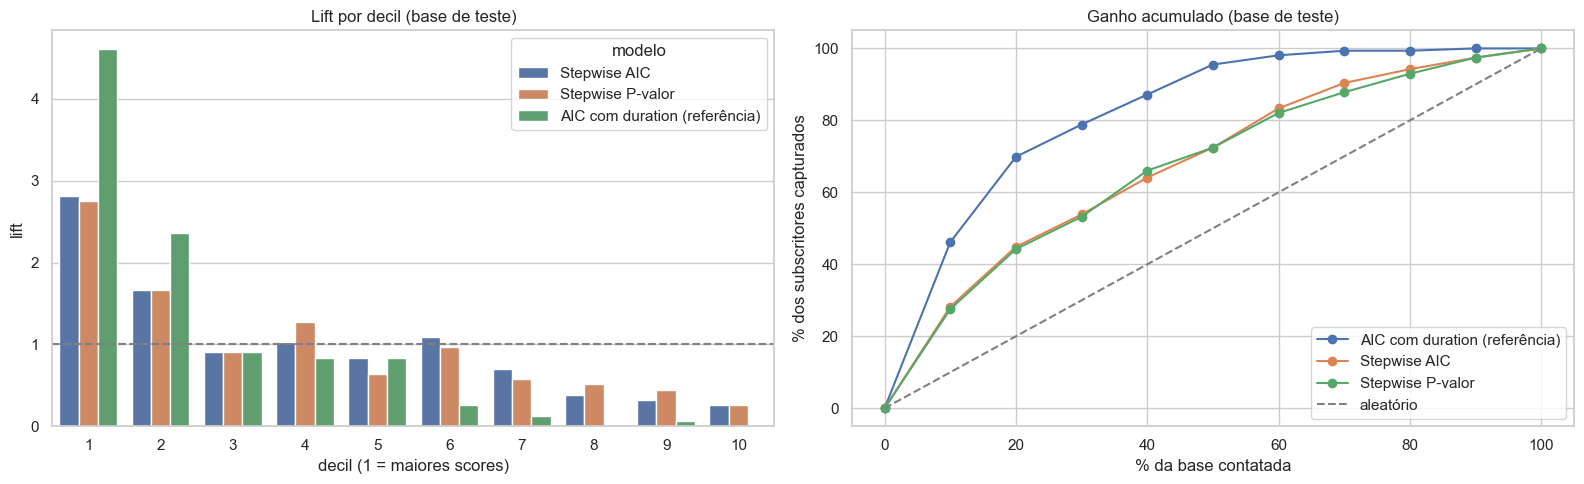

modelo,AIC com duration (referência),Stepwise AIC,Stepwise P-valor
decil,,,
1,4.6052,2.8143,2.7503
2,2.3666,1.6630,1.6630
3,0.9021,0.9021,0.9021
4,0.8315,1.0234,1.2792
5,0.8315,0.8315,0.6396
6,0.2577,1.0954,0.9665
7,0.1279,0.7036,0.5757
8,0.0000,0.3866,0.5155
9,0.0640,0.3198,0.4477


In [29]:
def tabela_lift(y, p, n_faixas=10):
    df = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    df['decil'] = pd.qcut(df['p'].rank(method='first', ascending=False), n_faixas, labels=False) + 1
    tab = df.groupby('decil').agg(n=('y', 'size'), eventos=('y', 'sum'))
    tab['taxa'] = tab['eventos'] / tab['n']
    tab['lift'] = tab['taxa'] / df['y'].mean()
    tab['ganho_acumulado_%'] = tab['eventos'].cumsum() / tab['eventos'].sum() * 100
    return tab


lift = (pd.concat({nome: tabela_lift(y_teste, prever(modelo, X_teste_full))
                   for nome, modelo in MODELOS.items()}, names=['modelo'])
        .reset_index())

fig, (ax_lift, ax_ganho) = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=lift, x='decil', y='lift', hue='modelo', ax=ax_lift)
ax_lift.axhline(1, color='gray', linestyle='--')
ax_lift.set(title='Lift por decil (base de teste)', xlabel='decil (1 = maiores scores)', ylabel='lift')

for nome, grupo in lift.groupby('modelo'):
    ax_ganho.plot(np.r_[0, grupo['decil'] * 10], np.r_[0, grupo['ganho_acumulado_%']],
                  marker='o', label=nome)
ax_ganho.plot([0, 100], [0, 100], color='gray', linestyle='--', label='aleatório')
ax_ganho.set(title='Ganho acumulado (base de teste)', xlabel='% da base contatada',
             ylabel='% dos subscritores capturados')
ax_ganho.legend()
plt.tight_layout()
plt.show()

lift.pivot(index='decil', columns='modelo', values='lift')

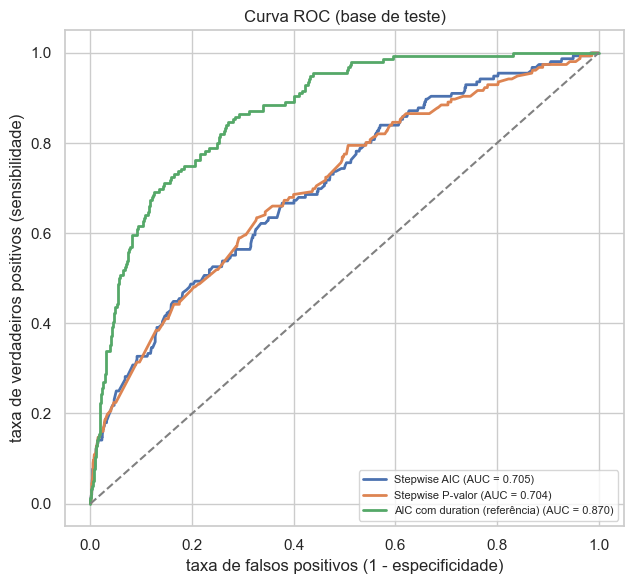

In [30]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for nome, modelo in MODELOS.items():
    p = prever(modelo, X_teste_full)
    fpr, tpr, _ = roc_curve(y_teste, p)
    ax.plot(fpr, tpr, lw=2, label=f'{nome} (AUC = {roc_auc_score(y_teste, p):.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax.set(title='Curva ROC (base de teste)', xlabel='taxa de falsos positivos (1 - especificidade)',
       ylabel='taxa de verdadeiros positivos (sensibilidade)')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 7. Conclusões

> Os números citados aqui dependem da execução do notebook; complete esta seção com os valores obtidos.

- **Escolha do modelo:** compare AUC, KS e lift dos dois modelos principais na base de teste. Se o desempenho for praticamente igual, o **Stepwise P-valor** é preferível por ser mais simples (menos variáveis, mais fácil de explicar e de manter).
- **Overfitting:** a diferença entre as métricas de treino e de teste mostra quanto o desempenho medido no próprio ajuste (como na versão em R) superestima o desempenho real.
- **Efeito de `duration`:** a distância entre o modelo de referência e os modelos principais mostra o quanto as métricas seriam infladas por uma variável indisponível no momento da decisão.
- **Ponto de corte:** cortes próximos da taxa de eventos (≈ 0,1–0,2) ou o de máximo KS equilibram melhor precision e recall do que os cortes 0,4–0,6 usados originalmente.
- **Ordenação:** o primeiro decil e a curva de ganho mostram, de forma direta para o negócio, quantos subscritores a campanha encontra contatando apenas uma parte da base.

**Próximos passos possíveis:**
- Usar `month` (ou trimestres) em vez de semestre, já que a taxa de subscrição varia bastante entre os meses (seção 3.3).
- Usar validação cruzada em vez de uma única divisão treino/teste.
- Comparar com modelos não lineares (árvores, gradient boosting).